# 09_ROCOv2_Counterfactual_Explanations

**Purpose:** Latent-space counterfactual explanations for the Proposed VLM
(Notebook 07) — for a given sample and label, find the minimal
perturbation in the model's fused image+caption embedding space that
flips its decision, then explain that perturbation with a **real**
retrieved training example rather than a synthetically generated image.

### Methodology (confirmed, not assumed)
- **Scope:** Proposed VLM (07) only — the fine-tuned BiomedCLIP + fusion
  head. Not applied to DenseNet121 or the zero-shot BiomedCLIP baseline.
- **Counterfactual search:** gradient-based search directly in the
  **fused embedding space** that Notebook 07's classifier head actually
  consumes (`concat(normalize(image_embed), normalize(text_embed))`).
  BiomedCLIP's backbone is frozen and not touched by the search — only the
  small fusion head (already frozen/trained) is used to compute gradients
  with respect to a perturbation `δ` of the fused vector. This is fast:
  each step is a forward/backward pass through a two-layer MLP, not the
  195M-parameter backbone.
- **Minimality:** search stops as soon as the perturbed point crosses the
  label's decision boundary (probability crosses 0.5) rather than
  continuing to an extreme — the reported distance (`‖δ‖`) is the
  approximate minimal perturbation needed to flip that specific decision.
  Non-convergence within the step budget is reported explicitly, never
  silently treated as a valid distance.
- **Explanation, not generation:** the counterfactual latent point is used
  only to retrieve the nearest **real** Train image+caption (by embedding
  distance) for visualization. No synthetic/hallucinated medical image is
  ever generated — a deliberate choice for scientific and clinical safety.
- **Two parts:**
  - **Part A (quantitative):** for a fixed-seed sample of Test-final,
    compute the counterfactual distance for every one of the 18 labels —
    a per-label "distance to decision boundary" table/figure, a measure of
    decision robustness.
  - **Part B (qualitative):** using Part A's own results, select the most
    fragile (smallest distance) and most robust (largest distance) cases
    and produce an illustrative figure: original sample vs. its retrieved
    real counterfactual neighbor.

### Inputs
- `Prepared/train_prepared.csv`, `test_final_prepared.csv` (Notebook 08 —
  **not** the original `test_prepared.csv`, since Test-final is the
  correct untouched-and-final evaluation split from this point onward),
  `label_mapping.json`.
- `Prepared/Baselines/BiomedCLIP_VLM_Trained/checkpoints/vlm_best_model.pt`
  and `vlm_config.json` (Notebook 07 — loaded read-only, never re-trained).

### Outputs
Under `Prepared/CounterfactualExplanations/`: cached Train fused
embeddings (reusable), per-label counterfactual distance statistics,
qualitative case-study figure, config, reproducibility record, manifest.

### Non-goals
No XAI/attribution methods (Grad-CAM, attention maps — Notebook 10), no
trust score. No modification of any previous notebook or model.

In [11]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import os
import io
import sys
import json
import time
import random
import zipfile
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

CF_DIR = PREPARED_DIR / "CounterfactualExplanations"
FIG_DIR = CF_DIR / "figures"
for d in [CF_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TRAIN_PREPARED_PATH = PREPARED_DIR / "train_prepared.csv"
TEST_FINAL_PREPARED_PATH = PREPARED_DIR / "test_final_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"

VLM_DIR = PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_Trained"
VLM_BEST_MODEL_PATH = VLM_DIR / "checkpoints" / "vlm_best_model.pt"
VLM_CONFIG_PATH = VLM_DIR / "vlm_config.json"

IMAGE_ZIP_FILES = {
    "train": ROCO_ROOT / "Train" / "Images" / "train_images.zip",
    "test": ROCO_ROOT / "Test" / "Images" / "test_images.zip",
}

TRAIN_EMBEDDINGS_PATH = CF_DIR / "train_fused_embeddings.npy"
TRAIN_EMBEDDINGS_IDS_PATH = CF_DIR / "train_fused_embeddings_ids.csv"
QUANT_RESULTS_PATH = CF_DIR / "counterfactual_distance_per_label_sample.csv"
QUANT_SUMMARY_PATH = CF_DIR / "counterfactual_distance_summary.csv"
QUANT_FIGURE_PDF = FIG_DIR / "counterfactual_distance_by_label.pdf"
QUANT_FIGURE_PNG = FIG_DIR / "counterfactual_distance_by_label_300dpi.png"
CASE_STUDY_FIGURE_PDF = FIG_DIR / "counterfactual_case_studies.pdf"
CASE_STUDY_FIGURE_PNG = FIG_DIR / "counterfactual_case_studies_300dpi.png"
CASE_STUDY_TABLE_PATH = CF_DIR / "counterfactual_case_studies.csv"
CF_CONFIG_PATH = CF_DIR / "counterfactual_config.json"
REPRODUCIBILITY_PATH = CF_DIR / "reproducibility.json"
MANIFEST_PATH = CF_DIR / "artifact_manifest.json"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

QUANT_SAMPLE_SIZE = 500
CF_MAX_STEPS = 500
CF_LR = 0.05
CF_L2_WEIGHT = 0.01
N_CASE_STUDIES_PER_EXTREME = 3

print("=" * 80)
print("NOTEBOOK 09 — COUNTERFACTUAL EXPLANATIONS (LATENT, PROPOSED VLM)")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("CF_DIR:", CF_DIR)
print("Random seed:", SEED)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive available.
NOTEBOOK 09 — COUNTERFACTUAL EXPLANATIONS (LATENT, PROPOSED VLM)
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
CF_DIR: /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations
Random seed: 42


## 1. Verify required inputs

Requires Notebook 07's trained checkpoint and Notebook 08's Test-final
split — **not** the original `test_prepared.csv`, since Test-final is the
correct final-evaluation split from Notebook 08 onward.

In [2]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "train_prepared.csv": TRAIN_PREPARED_PATH,
    "test_final_prepared.csv": TEST_FINAL_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
    "vlm_best_model.pt": VLM_BEST_MODEL_PATH,
    "vlm_config.json": VLM_CONFIG_PATH,
}
missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 09 input artifacts are missing:\n\n" + "\n".join(missing_inputs)
        + "\n\nRun 02, 07, and 08 first."
    )

for name, path in IMAGE_ZIP_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Original image ZIP missing for {name}: {path}")

print("PASS — Required Notebook 02/07/08 artifacts and original image ZIPs exist.")


PASS — Required Notebook 02/07/08 artifacts and original image ZIPs exist.


## 2. Load splits and label taxonomy

In [3]:
# ============================================================
# CELL 3 — LOAD SPLITS AND LABEL MAPPING
# ============================================================

train_df = pd.read_csv(TRAIN_PREPARED_PATH)
test_final_df = pd.read_csv(TEST_FINAL_PREPARED_PATH)

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

assert len(label_mapping) == 18, "Authoritative label_mapping.json must contain exactly 18 labels."
LABEL_COLUMNS = [f"label_{cui}" for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
N_LABELS = len(LABEL_COLUMNS)

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

print(f"Train: {len(train_df):,} | Test-final: {len(test_final_df):,}")
print(f"Label taxonomy: {N_LABELS} labels.")


Train: 59,666 | Test-final: 4,935
Label taxonomy: 18 labels.


## 3. Load the Proposed VLM (Notebook 07's best checkpoint, read-only)

Loaded exactly as trained — backbone and fusion head both frozen, eval
mode. Nothing here is fine-tuned further.

In [4]:
# ============================================================
# CELL 4 — LOAD PROPOSED VLM (read-only)
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

with open(VLM_CONFIG_PATH, "r", encoding="utf-8") as f:
    vlm_config = json.load(f)

BIOMEDCLIP_CHECKPOINT = vlm_config["architecture"]["backbone_checkpoint"]

try:
    import open_clip
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"], check=True)
    import open_clip

biomedclip_model, biomedclip_preprocess = open_clip.create_model_from_pretrained(BIOMEDCLIP_CHECKPOINT)
biomedclip_tokenizer = open_clip.get_tokenizer(BIOMEDCLIP_CHECKPOINT)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biomedclip_model = biomedclip_model.to(device)

fusion_dim = vlm_config["training_config"]["fusion_dim"]
classifier_head = nn.Sequential(
    nn.Linear(fusion_dim, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, N_LABELS),
).to(device)

checkpoint = torch.load(VLM_BEST_MODEL_PATH, map_location=device)
biomedclip_model.load_state_dict(checkpoint["backbone_state_dict"])
classifier_head.load_state_dict(checkpoint["head_state_dict"])

biomedclip_model.eval()
classifier_head.eval()
for p in biomedclip_model.parameters():
    p.requires_grad = False
for p in classifier_head.parameters():
    p.requires_grad = False

print(f"Loaded Proposed VLM from: {VLM_BEST_MODEL_PATH}")
print(f"Checkpoint epoch={checkpoint['epoch']}, stage={checkpoint['stage']}, "
      f"validation_macro_f1={checkpoint['validation_macro_f1']:.4f}")
print("Both backbone and fusion head frozen (eval mode) — nothing is trained in this notebook.")


open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

Loaded Proposed VLM from: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained/checkpoints/vlm_best_model.pt
Checkpoint epoch=12, stage=2, validation_macro_f1=0.8583
Both backbone and fusion head frozen (eval mode) — nothing is trained in this notebook.


## 4. Extract source ZIPs to plain local files (proven pattern)

In [5]:
# ============================================================
# CELL 5 — EXTRACT ZIPS TO PLAIN LOCAL FILES
# ============================================================

LOCAL_IMAGE_DIR = Path("/content/rocov2_images_local")
LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

EXTRACTED_IMAGE_DIRS = {
    split_name: LOCAL_IMAGE_DIR / f"{split_name}_extracted"
    for split_name in IMAGE_ZIP_FILES
}

def _extract_if_needed(zip_path, extract_dir, expected_members):
    extract_dir.mkdir(parents=True, exist_ok=True)
    existing = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if existing >= len(expected_members):
        print(f"Already extracted, skipping: {extract_dir} ({existing:,} files present)")
        return
    print(f"Extracting {zip_path.name} -> {extract_dir} ({len(expected_members):,} members)...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)
    extracted = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if extracted != len(expected_members):
        raise IOError(
            f"Extraction count mismatch for {zip_path.name}: expected "
            f"{len(expected_members):,}, found {extracted:,} under {extract_dir}."
        )
    print(f"  done: {extracted:,} files extracted.")

for split_name, zip_path in IMAGE_ZIP_FILES.items():
    with zipfile.ZipFile(zip_path, "r") as _zf:
        _members = [n for n in _zf.namelist() if not n.endswith("/")]
    _extract_if_needed(zip_path, EXTRACTED_IMAGE_DIRS[split_name], _members)

class LocalImageReader:
    def __init__(self, extract_dir):
        self.extract_dir = Path(extract_dir)

    def read_bytes(self, member):
        return (self.extract_dir / member).read_bytes()

image_readers = {s: LocalImageReader(EXTRACTED_IMAGE_DIRS[s]) for s in IMAGE_ZIP_FILES}
print("PASS — local image readers ready.")


Extracting train_images.zip -> /content/rocov2_images_local/train_extracted (59,958 members)...
  done: 59,958 files extracted.
Extracting test_images.zip -> /content/rocov2_images_local/test_extracted (9,927 members)...
  done: 9,927 files extracted.
PASS — local image readers ready.


## 5. Fused embedding computation (image + caption -> classifier-head input)

Exactly reproduces Notebook 07's `forward_vlm` up to (but not including)
the classifier head: `concat(normalize(image_embed), normalize(text_embed))`.
This is the space the counterfactual search operates in.

In [6]:
# ============================================================
# CELL 6 — FUSED EMBEDDING COMPUTATION
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader

class ROCOv2EmbeddingDataset(Dataset):
    def __init__(self, df, image_reader, transform):
        self.df = df.reset_index(drop=True)
        self.image_reader = image_reader
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        raw_bytes = self.image_reader.read_bytes(row["Image_Member"])
        with Image.open(io.BytesIO(raw_bytes)) as img:
            image = self.transform(img.convert("RGB"))
        return image, str(row["Caption"]), row["ID"]

@torch.no_grad()
def compute_fused_embeddings(df, image_reader, batch_size=32, num_workers=2):
    dataset = ROCOv2EmbeddingDataset(df, image_reader, biomedclip_preprocess)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

    all_embeds, all_ids = [], []
    for images, captions, ids in loader:
        images = images.to(device)
        text_tokens = biomedclip_tokenizer(list(captions)).to(device)
        image_embeds = F.normalize(biomedclip_model.encode_image(images), dim=-1)
        text_embeds = F.normalize(biomedclip_model.encode_text(text_tokens), dim=-1)
        fused = torch.cat([image_embeds, text_embeds], dim=-1)
        all_embeds.append(fused.cpu().numpy())
        all_ids.extend(list(ids))

    return np.concatenate(all_embeds, axis=0), all_ids

print("compute_fused_embeddings() defined.")


compute_fused_embeddings() defined.


## 6. Cache Train fused embeddings (one-time, reusable)

Used only for nearest-neighbor retrieval in Part B — reused across runs
rather than recomputed.

In [7]:
# ============================================================
# CELL 7 — CACHE TRAIN FUSED EMBEDDINGS (reuse-if-exists)
# ============================================================

if TRAIN_EMBEDDINGS_PATH.exists() and TRAIN_EMBEDDINGS_IDS_PATH.exists():
    train_embeddings = np.load(TRAIN_EMBEDDINGS_PATH)
    train_embedding_ids = pd.read_csv(TRAIN_EMBEDDINGS_IDS_PATH)["ID"].astype(str).tolist()
    if len(train_embedding_ids) == len(train_df):
        print(f"REUSING existing artifact — not recomputing: {TRAIN_EMBEDDINGS_PATH}")
    else:
        print("WARNING — cached Train embeddings do not match current Train row count. Recomputing.")
        train_embeddings = None
else:
    train_embeddings = None

if train_embeddings is None:
    print(f"Computing fused embeddings for {len(train_df):,} Train samples "
          "(one-time; this is the most expensive cell in this notebook)...")
    train_embeddings, train_embedding_ids = compute_fused_embeddings(train_df, image_readers["train"])
    np.save(TRAIN_EMBEDDINGS_PATH, train_embeddings)
    pd.DataFrame({"ID": train_embedding_ids}).to_csv(TRAIN_EMBEDDINGS_IDS_PATH, index=False)
    print("Saved:", TRAIN_EMBEDDINGS_PATH)
    print("Saved:", TRAIN_EMBEDDINGS_IDS_PATH)

train_id_to_row = pd.Series(train_df.index.values, index=train_df["ID"].astype(str)).to_dict()
train_embeddings_t = torch.from_numpy(train_embeddings).to(device)

print(f"\nTrain embedding matrix shape: {train_embeddings.shape}")


Computing fused embeddings for 59,666 Train samples (one-time; this is the most expensive cell in this notebook)...
Saved: /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations/train_fused_embeddings.npy
Saved: /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations/train_fused_embeddings_ids.csv

Train embedding matrix shape: (59666, 1024)


## 7. Latent counterfactual search function

Gradient descent on a perturbation `δ` of the fused embedding, minimizing
distance-to-original plus a loss pushing the label's probability across
0.5 in the direction opposite the model's current decision. Stops as soon
as the boundary is crossed.

In [8]:
# ============================================================
# CELL 8 — LATENT COUNTERFACTUAL SEARCH FUNCTION
# ============================================================

def find_latent_counterfactual(z0_np, label_idx, max_steps=CF_MAX_STEPS, lr=CF_LR, l2_weight=CF_L2_WEIGHT):
    z0 = torch.tensor(z0_np, dtype=torch.float32, device=device)
    with torch.no_grad():
        original_prob = torch.sigmoid(classifier_head(z0.unsqueeze(0))[0, label_idx]).item()
    target_direction = 1.0 if original_prob < 0.5 else 0.0

    z = z0.clone().detach().requires_grad_(True)
    optimizer = torch.optim.Adam([z], lr=lr)

    converged = False
    final_prob = original_prob
    steps_taken = 0

    for step in range(max_steps):
        optimizer.zero_grad()
        logit = classifier_head(z.unsqueeze(0))[0, label_idx]
        prob = torch.sigmoid(logit)
        flip_loss = (prob - target_direction) ** 2
        dist_loss = l2_weight * torch.sum((z - z0) ** 2)
        loss = flip_loss + dist_loss
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            final_prob = torch.sigmoid(classifier_head(z.unsqueeze(0))[0, label_idx]).item()
        steps_taken = step + 1

        crossed = (target_direction == 1.0 and final_prob >= 0.5) or (target_direction == 0.0 and final_prob < 0.5)
        if crossed:
            converged = True
            break

    distance = float(torch.norm(z.detach() - z0).item())
    z_cf = z.detach().cpu().numpy()

    return {
        "original_prob": original_prob,
        "final_prob": final_prob,
        "target_direction": target_direction,
        "converged": converged,
        "steps_taken": steps_taken,
        "distance": distance,
        "z_cf": z_cf,
    }

print("find_latent_counterfactual() defined — stops as soon as the decision boundary is crossed.")


find_latent_counterfactual() defined — stops as soon as the decision boundary is crossed.


## 8. Part A — quantitative counterfactual distance analysis

A fixed-seed sample of Test-final, all 18 labels per sample — a per-label
"distance to decision boundary" measure of how robust each label's
decisions are.

In [17]:
print("Current value:", CF_MAX_STEPS)
CF_MAX_STEPS = 500
ALLOW_OVERWRITE = True



Current value: 500


In [18]:
# ============================================================
# CELL 9 — PART A: QUANTITATIVE COUNTERFACTUAL DISTANCE ANALYSIS
# ============================================================

sample_size = min(QUANT_SAMPLE_SIZE, len(test_final_df))
quant_sample_df = test_final_df.sample(n=sample_size, random_state=SEED).reset_index(drop=True)

print(f"Computing fused embeddings for {len(quant_sample_df):,} Test-final samples...")
quant_embeddings, quant_ids = compute_fused_embeddings(quant_sample_df, image_readers["test"])
quant_id_to_embed = dict(zip(quant_ids, quant_embeddings))

quant_rows = []
_start = time.time()
for i, row in quant_sample_df.iterrows():
    sample_id = str(row["ID"])
    z0 = quant_id_to_embed[sample_id]
    for label_idx, label_name in enumerate(LABEL_NAMES):
        result = find_latent_counterfactual(z0, label_idx)
        quant_rows.append({
            "ID": sample_id, "Label_Name": label_name,
            "True_Label": int(row[LABEL_COLUMNS[label_idx]]),
            "Original_Prob": result["original_prob"], "Final_Prob": result["final_prob"],
            "Converged": result["converged"], "Steps_Taken": result["steps_taken"],
            "Counterfactual_Distance": result["distance"],
        })

print(f"Done in {time.time() - _start:.1f}s — {len(quant_rows):,} (sample x label) counterfactual searches.")

quant_results_df = pd.DataFrame(quant_rows)
safe_save_csv(QUANT_RESULTS_PATH, quant_results_df)


Computing fused embeddings for 500 Test-final samples...
Done in 330.5s — 9,000 (sample x label) counterfactual searches.
Saved: /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations/counterfactual_distance_per_label_sample.csv


## 9. Quantitative results — per-label summary and figure

Non-convergent searches (did not cross the boundary within the step
budget) are reported and excluded from the mean-distance calculation
explicitly, never silently averaged in as if they were valid.

Saved: /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations/counterfactual_distance_summary.csv


,Label_Name,N_Samples,N_Converged,Pct_Converged,Mean_Counterfactual_Distance,Median_Counterfactual_Distance
9,X-Ray Computed Tomography,500,489,97.8,1.455146,1.586607
4,Magnetic Resonance Imaging,500,500,100.0,1.401492,1.576907
0,Abdomen,500,500,100.0,1.374761,1.563666
13,Chest,500,498,99.6,1.366138,1.560491
12,Sagittal,500,500,100.0,1.317785,1.520004
5,Pelvis,500,500,100.0,1.273865,1.472661
8,Vertebral column,500,500,100.0,1.257079,1.427623
11,Transverse,500,104,20.8,1.166764,1.248406
16,Postero-Anterior,500,433,86.6,1.165853,1.193475
10,Ultrasonography,500,444,88.8,1.144214,1.211679


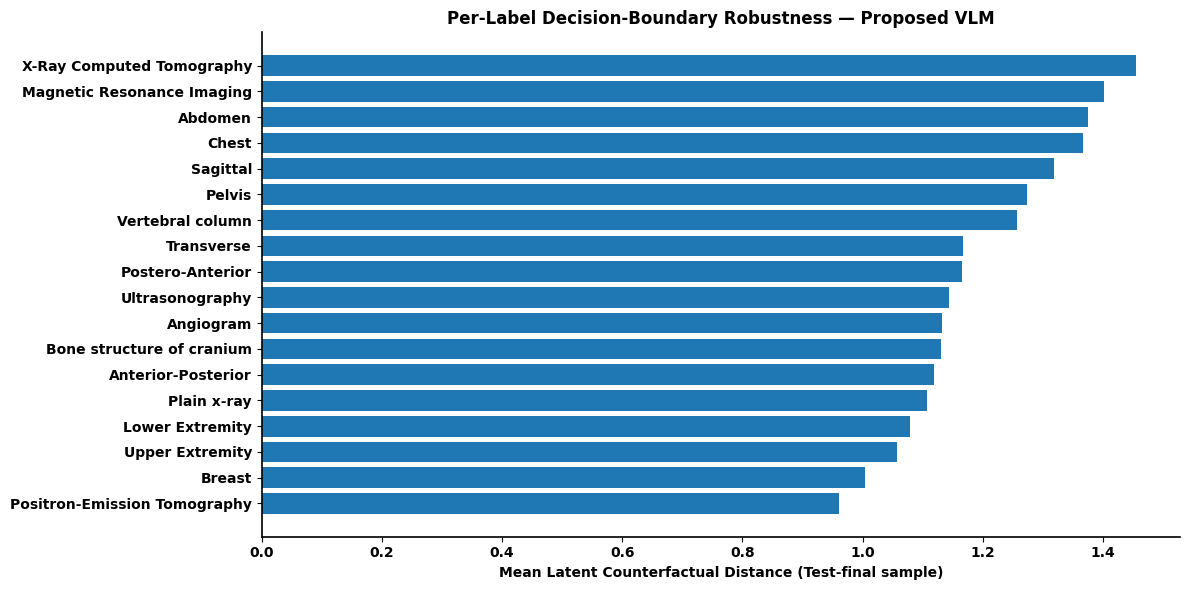

Saved: /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations/figures/counterfactual_distance_by_label.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations/figures/counterfactual_distance_by_label_300dpi.png


In [19]:
# ============================================================
# CELL 10 — QUANTITATIVE SUMMARY AND FIGURE
# ============================================================

summary_rows = []
for label_name in LABEL_NAMES:
    subset = quant_results_df.loc[quant_results_df["Label_Name"] == label_name]
    converged_subset = subset.loc[subset["Converged"]]
    summary_rows.append({
        "Label_Name": label_name,
        "N_Samples": len(subset),
        "N_Converged": len(converged_subset),
        "Pct_Converged": 100.0 * len(converged_subset) / len(subset) if len(subset) else np.nan,
        "Mean_Counterfactual_Distance": converged_subset["Counterfactual_Distance"].mean(),
        "Median_Counterfactual_Distance": converged_subset["Counterfactual_Distance"].median(),
    })

quant_summary_df = pd.DataFrame(summary_rows).sort_values("Mean_Counterfactual_Distance", ascending=False)
safe_save_csv(QUANT_SUMMARY_PATH, quant_summary_df)
display(quant_summary_df)

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.linewidth": 1.2,
})

fig, ax = plt.subplots(figsize=(12, 6))
plot_df = quant_summary_df.sort_values("Mean_Counterfactual_Distance")
ax.barh(plot_df["Label_Name"], plot_df["Mean_Counterfactual_Distance"], color="#1f77b4")
ax.set_xlabel("Mean Latent Counterfactual Distance (Test-final sample)")
ax.set_title("Per-Label Decision-Boundary Robustness — Proposed VLM", fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(QUANT_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(QUANT_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", QUANT_FIGURE_PDF)
print("Saved:", QUANT_FIGURE_PNG)


## 10. Part B — qualitative case studies

Selected objectively from Part A's own results: the most fragile
(smallest counterfactual distance — decisions closest to the boundary) and
most robust (largest distance) converged cases, not cherry-picked.

In [ ]:
# ============================================================
# CELL 11 — PART B: SELECT CASE STUDIES AND RETRIEVE REAL NEAREST NEIGHBORS
# ============================================================

converged_results = quant_results_df.loc[quant_results_df["Converged"]].copy()

most_fragile = converged_results.nsmallest(N_CASE_STUDIES_PER_EXTREME, "Counterfactual_Distance")
most_robust = converged_results.nlargest(N_CASE_STUDIES_PER_EXTREME, "Counterfactual_Distance")
case_selection = pd.concat([most_fragile.assign(Case_Type="Most fragile"),
                             most_robust.assign(Case_Type="Most robust")], ignore_index=True)

case_rows = []
for _, case in case_selection.iterrows():
    sample_id = case["ID"]
    label_idx = LABEL_NAMES.index(case["Label_Name"])
    z0 = quant_id_to_embed[sample_id]

    result = find_latent_counterfactual(z0, label_idx)
    z_cf = result["z_cf"]

    z_cf_t = torch.tensor(z_cf, dtype=torch.float32, device=device)
    distances = torch.norm(train_embeddings_t - z_cf_t.unsqueeze(0), dim=1)
    nn_idx = int(torch.argmin(distances).item())
    nn_id = train_embedding_ids[nn_idx]
    nn_distance = float(distances[nn_idx].item())

    original_row = test_final_df.loc[test_final_df["ID"].astype(str) == sample_id].iloc[0]
    neighbor_row = train_df.loc[train_df["ID"].astype(str) == nn_id].iloc[0]

    case_rows.append({
        "Case_Type": case["Case_Type"], "Original_ID": sample_id, "Label_Name": case["Label_Name"],
        "Original_Caption": original_row["Caption"], "Original_Image_Member": original_row["Image_Member"],
        "Original_Prob": result["original_prob"], "Counterfactual_Distance": result["distance"],
        "Neighbor_ID": nn_id, "Neighbor_Caption": neighbor_row["Caption"],
        "Neighbor_Image_Member": neighbor_row["Image_Member"],
        "Neighbor_True_Label_Value": int(neighbor_row[LABEL_COLUMNS[label_idx]]),
        "Neighbor_Distance_To_Counterfactual_Point": nn_distance,
    })

case_studies_df = pd.DataFrame(case_rows)
safe_save_csv(CASE_STUDY_TABLE_PATH, case_studies_df)
display(case_studies_df[["Case_Type", "Original_ID", "Label_Name", "Original_Prob",
                          "Counterfactual_Distance", "Neighbor_ID", "Neighbor_True_Label_Value"]])


## 11. Publication-quality case-study figure

Original sample (with its prediction) alongside its retrieved real
counterfactual neighbor — no synthetic image anywhere in this figure.

In [ ]:
# ============================================================
# CELL 12 — CASE STUDY FIGURE
# ============================================================

n_cases = len(case_studies_df)
fig, axes = plt.subplots(n_cases, 2, figsize=(10, 4.2 * n_cases))
if n_cases == 1:
    axes = axes.reshape(1, 2)

for row_i, case in case_studies_df.iterrows():
    orig_bytes = image_readers["test"].read_bytes(case["Original_Image_Member"])
    neighbor_bytes = image_readers["train"].read_bytes(case["Neighbor_Image_Member"])

    with Image.open(io.BytesIO(orig_bytes)) as img:
        axes[row_i, 0].imshow(img.convert("RGB"))
    axes[row_i, 0].set_title(
        f"[{case['Case_Type']}] Original — {case['Label_Name']}\n"
        f"P={case['Original_Prob']:.3f} | \"{str(case['Original_Caption'])[:60]}...\"",
        fontsize=8,
    )
    axes[row_i, 0].axis("off")

    with Image.open(io.BytesIO(neighbor_bytes)) as img:
        axes[row_i, 1].imshow(img.convert("RGB"))
    axes[row_i, 1].set_title(
        f"Nearest real counterfactual neighbor (Train)\n"
        f"dist={case['Counterfactual_Distance']:.3f} | \"{str(case['Neighbor_Caption'])[:60]}...\"",
        fontsize=8,
    )
    axes[row_i, 1].axis("off")

fig.suptitle("Latent Counterfactual Explanations — Proposed VLM\n"
             "(retrieved real training examples, no synthetic generation)", fontweight="bold")
fig.tight_layout()
fig.savefig(CASE_STUDY_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(CASE_STUDY_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", CASE_STUDY_FIGURE_PDF)
print("Saved:", CASE_STUDY_FIGURE_PNG)


## 12. Save configuration and reproducibility record

In [ ]:
# ============================================================
# CELL 13 — SAVE CONFIG AND REPRODUCIBILITY.JSON
# ============================================================

cf_config = {
    "method": "Latent-space gradient-based counterfactual search + real nearest-neighbor retrieval",
    "scope": "Proposed VLM (Notebook 07) only",
    "search_space": "concat(normalize(image_embed), normalize(text_embed)) — classifier head input",
    "max_steps": CF_MAX_STEPS, "learning_rate": CF_LR, "l2_weight": CF_L2_WEIGHT,
    "stopping_rule": "as soon as the perturbed point crosses the 0.5 decision boundary",
    "quantitative_sample_size": int(sample_size),
    "case_studies_per_extreme": N_CASE_STUDIES_PER_EXTREME,
    "nearest_neighbor_reference_set": "Train (all samples, cached fused embeddings)",
    "label_columns": LABEL_COLUMNS, "label_names": LABEL_NAMES,
}
safe_save_json(CF_CONFIG_PATH, cf_config)

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

reproducibility = {
    "notebook": "09_ROCOv2_Counterfactual_Explanations",
    "python_version": sys.version, "platform": platform.platform(),
    "pytorch_version": torch.__version__, "open_clip_version": package_version("open_clip"),
    "numpy_version": np.__version__, "pandas_version": pd.__version__,
    "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "random_seed": SEED, "source_checkpoint": str(VLM_BEST_MODEL_PATH),
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


## 13. Artifact manifest and final report

In [ ]:
# ============================================================
# CELL 14 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    TRAIN_EMBEDDINGS_PATH, TRAIN_EMBEDDINGS_IDS_PATH, QUANT_RESULTS_PATH, QUANT_SUMMARY_PATH,
    QUANT_FIGURE_PDF, QUANT_FIGURE_PNG, CASE_STUDY_TABLE_PATH, CASE_STUDY_FIGURE_PDF,
    CASE_STUDY_FIGURE_PNG, CF_CONFIG_PATH, REPRODUCIBILITY_PATH,
]
manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"
safe_save_json(MANIFEST_PATH, {"artifacts": manifest, "status": notebook_status})

n_non_converged = int((~quant_results_df["Converged"]).sum())

print("\n" + "=" * 60)
print("ROCOv2 COUNTERFACTUAL EXPLANATIONS")
print("FINAL REPORT")
print("=" * 60)
print(f'''
Model:
Proposed VLM (fine-tuned BiomedCLIP), Notebook 07's best checkpoint

Method:
Latent-space gradient counterfactual search + real nearest-neighbor retrieval

Quantitative sample size:
{sample_size:,} Test-final samples x {N_LABELS} labels = {len(quant_results_df):,} searches

Non-converged searches (reported, not hidden):
{n_non_converged:,} / {len(quant_results_df):,}

Case studies:
{n_cases} ({N_CASE_STUDIES_PER_EXTREME} most fragile + {N_CASE_STUDIES_PER_EXTREME} most robust)

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Counterfactual explanations implemented:
YES (latent search, Proposed VLM only)

Synthetic images generated:
NO — all visualized counterfactuals are real retrieved Train examples

Previous notebooks modified:
NO

Model re-trained:
NO — checkpoint loaded read-only

Ready for XAI notebook:
{"YES" if not manifest_missing else "NO"}
''')
print("=" * 60)

print("\nSTOP — Notebook 09 (Counterfactual Explanations) is complete.")
print("Not implemented here (by design): XAI/attribution methods, Trust Score.")
print("Next notebook: 10_ROCOv2_XAI.ipynb")
